<a href="https://colab.research.google.com/github/abbasshaik-ops/DD/blob/main/Crop_Health_Disease_Monitoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

print("Crop Health and Disease Monitoring")
print("Project setup successful!")

import tensorflow as tf
print("TensorFlow version:", tf.__version__)


Crop Health and Disease Monitoring
Project setup successful!
TensorFlow version: 2.21.0


In [ ]:

!pip install -q tensorflow-datasets

In [ ]:

import tensorflow as tf
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names

tomato_classes = [
    (i, name)
    for i, name in enumerate(class_names)
    if name.startswith("Tomato___")
]

print("Total dataset images:", info.splits["train"].num_examples)
print("\nTomato disease classes:")

for class_id, name in tomato_classes:
    print(class_id, ":", name)


ModuleNotFoundError: No module named 'importlib_resources'

In [ ]:

%pip install -q importlib-resources


In [ ]:

import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Total images:", info.splits["train"].num_examples)
print("Label names:", info.features["label"].names)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

DownloadError: Failed to get url https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/d5652a28-c1d8-4b76-97f3-72fb80f94efc/file_downloaded. HTTP code: 403.

In [ ]:

%pip install -q kagglehub


In [ ]:

import kagglehub
import os

path = kagglehub.dataset_download("emmarex/plantdisease")

print("Dataset downloaded successfully!")
print("Dataset location:", path)
print("Files and folders:", os.listdir(path)[:20])


Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/plantdisease
Files and folders: ['PlantVillage', 'plantvillage']


In [ ]:

import os

for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)

    if depth <= 2:
        print(
            "  " * depth,
            os.path.basename(root) or root,
            "-",
            len(files),
            "files"
        )

    if depth >= 2:
        dirs[:] = []


 plantdisease - 0 files
   PlantVillage - 0 files
     Pepper__bell___Bacterial_spot - 997 files
     Potato___healthy - 152 files
     Tomato_Leaf_Mold - 952 files
     Tomato__Tomato_YellowLeaf__Curl_Virus - 3209 files
     Tomato_Bacterial_spot - 2127 files
     Tomato_Septoria_leaf_spot - 1771 files
     Tomato_healthy - 1591 files
     Tomato_Spider_mites_Two_spotted_spider_mite - 1676 files
     Tomato_Early_blight - 1000 files
     Tomato__Target_Spot - 1404 files
     Pepper__bell___healthy - 1478 files
     Potato___Late_blight - 1000 files
     Tomato_Late_blight - 1909 files
     Potato___Early_blight - 1000 files
     Tomato__Tomato_mosaic_virus - 373 files
   plantvillage - 0 files
     PlantVillage - 0 files


In [ ]:

import os

print("Dataset path:", path)

for root, dirs, files in os.walk(path):
    image_count = sum(
        f.lower().endswith((".jpg", ".jpeg", ".png"))
        for f in files
    )

    if image_count > 0:
        print(root, "->", image_count, "images")


Dataset path: /kaggle/input/plantdisease
/kaggle/input/plantdisease/PlantVillage/Pepper__bell___Bacterial_spot -> 997 images
/kaggle/input/plantdisease/PlantVillage/Potato___healthy -> 152 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Leaf_Mold -> 952 images
/kaggle/input/plantdisease/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus -> 3208 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Bacterial_spot -> 2127 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Septoria_leaf_spot -> 1771 images
/kaggle/input/plantdisease/PlantVillage/Tomato_healthy -> 1591 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite -> 1676 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Early_blight -> 1000 images
/kaggle/input/plantdisease/PlantVillage/Tomato__Target_Spot -> 1404 images
/kaggle/input/plantdisease/PlantVillage/Pepper__bell___healthy -> 1478 images
/kaggle/input/plantdisease/PlantVillage/Potato___Late_blight -> 1000 images
/kaggle/i

In [ ]:

import os
import tensorflow as tf

# Locate the folder containing tomato disease classes
data_dir = None

for root, dirs, files in os.walk(path):
    if "Tomato_healthy" in dirs:
        data_dir = root
        break

if data_dir is None:
    for root, dirs, files in os.walk(path):
        if "Tomato___healthy" in dirs:
            data_dir = root
            break

if data_dir is None:
    raise FileNotFoundError(
        "Tomato class folders not found. Check Step 4A output."
    )

print("Using folder:", data_dir)
print("Tomato classes:")

for folder in sorted(os.listdir(data_dir)):
    if folder.startswith("Tomato_") or folder.startswith("Tomato___"):
        print(folder)


Using folder: /kaggle/input/plantdisease/PlantVillage
Tomato classes:
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_YellowLeaf__Curl_Virus
Tomato__Tomato_mosaic_virus
Tomato_healthy


In [ ]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels="inferred",
    label_mode="int",
    class_names=sorted([
        name for name in os.listdir(data_dir)
        if name.startswith(("Tomato_", "Tomato___"))
        and os.path.isdir(os.path.join(data_dir, name))
    ]),
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels="inferred",
    label_mode="int",
    class_names=train_ds.class_names,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

# Split the held-out 20% into validation and test sets
val_batches = tf.data.experimental.cardinality(temp_ds).numpy()
val_ds = temp_ds.take(val_batches // 2)
test_ds = temp_ds.skip(val_batches // 2)

print("\nClasses:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 16011 files belonging to 10 classes.
Using 12809 files for training.
Found 16011 files belonging to 10 classes.
Using 3202 files for validation.

Classes: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Training batches: 401
Validation batches: 50
Test batches: 51


In [ ]:

AUTOTUNE = tf.data.AUTOTUNE

def preprocess(images, labels):
    images = tf.keras.applications.mobilenet_v2.preprocess_input(
        tf.cast(images, tf.float32)
    )
    return images, labels

train_ds = train_ds.map(
    preprocess, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_ds.map(
    preprocess, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    preprocess, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Tomato dataset is ready for model training!")


Tomato dataset is ready for model training!


In [ ]:

import tensorflow as tf

num_classes = len(class_names)

# Load the pretrained MobileNetV2 feature extractor
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Create the disease classification model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5
401/401 ━━━━━━━━━━━━━━━━━━━━ 700s 2s/step - accuracy: 0.8631 - loss: 0.4250 - val_accuracy: 0.8900 - val_loss: 0.3412
Epoch 2/5
401/401 ━━━━━━━━━━━━━━━━━━━━ 713s 2s/step - accuracy: 0.8909 - loss: 0.3417 - val_accuracy: 0.8944 - val_loss: 0.3065
Epoch 3/5
401/401 ━━━━━━━━━━━━━━━━━━━━ 708s 2s/step - accuracy: 0.9002 - loss: 0.3069 - val_accuracy: 0.9006 - val_loss: 0.3016
Epoch 4/5
401/401 ━━━━━━━━━━━━━━━━━━━━ 740s 2s/step - accuracy: 0.9072 - loss: 0.2801 - val_accuracy: 0.9031 - val_loss: 0.2913
Epoch 5/5
401/401 ━━━━━━━━━━━━━━━━━━━━ 661s 2s/step - accuracy: 0.9158 - loss: 0.2636 - val_accuracy: 0.9062 - val_loss: 0.2692


In [ ]:

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


51/51 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.9070 - loss: 0.2980
Test loss: 0.2980
Test accuracy: 90.70%


In [ ]:

model.save("/content/crop_disease_model.keras")

print("Model saved successfully!")
print("Number of classes:", num_classes)
print("Disease classes:", class_names)


Model saved successfully!
Number of classes: 10
Disease classes: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os
import json
import shutil

project_dir = "/content/drive/MyDrive/Crop_Health_Project"
os.makedirs(project_dir, exist_ok=True)

# Copy the trained model to Google Drive
shutil.copy2(
    "/content/crop_disease_model.keras",
        f"{project_dir}/crop_disease_model.keras"
        )
with open(f"{project_dir}/class_names.json", "w") as f:
            json.dump(class_names, f)

            print("Project files saved to Google Drive!")
            print("Folder:", project_dir)
            print(os.listdir(project_dir))


Project files saved to Google Drive!
Folder: /content/drive/MyDrive/Crop_Health_Project
['crop_disease_model.keras', 'class_names.json']


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import tensorflow as tf
import json

# Load the saved model and its class names
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Crop_Health_Project/crop_disease_model.keras"
    )
with open(
        "/content/drive/MyDrive/Crop_Health_Project/class_names.json"
        ) as f:
            class_names = json.load(f)

            # Upload a leaf image from your tablet
            uploaded = files.upload()

            for filename in uploaded:
                image = Image.open(filename).convert("RGB")
                display(image.resize((300, 300)))

                image = image.resize((224, 224))
                image_array = np.array(image, dtype=np.float32)

                image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
                image_array
                                            )
                image_array = np.expand_dims(image_array, axis=0)

                predictions = model.predict(image_array, verbose=0)[0]
                best_index = int(np.argmax(predictions))

                print("Predicted class:", class_names[best_index])
                print(f"Model confidence: {predictions[best_index] * 100:.2f}%")


ValueError: File not found: filepath=/content/drive/MyDrive/Crop_Health_Project/crop_disease_model.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
print("Number of classes:", len(class_names))

for i, name in enumerate(class_names, start=1):
    print(f"{i}. {name}")

NameError: name 'class_names' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:

import os

project_dir = "/content/drive/MyDrive/Crop_Health_Project"

print("Files in project folder:")

for filename in os.listdir(project_dir):
    print(filename)


Files in project folder:
crop_disease_model.keras
class_names.json


In [ ]:

%pip install -q streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 44.8 MB/s eta 0:00:00


In [ ]:


!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &


In [ ]:

%pip install -q pyngrok


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for name in files:
            if name == 'crop_disease_model.keras':
                        print("Model found:", os.path.join(root, name))

Model found: /content/drive/MyDrive/Crop_Health_Project/crop_disease_model.keras


In [ ]:
import os

matches = []

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'crop_disease_model.keras' in files:
            matches.append(os.path.join(root, 'crop_disease_model.keras'))

            if matches:
                for path in matches:
                        print("MODEL PATH:", path)
                else:
                        print("Model not found in MyDrive")

MODEL PATH: /content/drive/MyDrive/Crop_Health_Project/crop_disease_model.keras
Model not found in MyDrive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive'):
    for name in files:
            if name.endswith(('.keras', '.h5', '.hdf5')):
                        print(os.path.join(root, name))

/content/drive/MyDrive/Crop_Health_Project/crop_disease_model.keras


In [ ]:
import os

for path in [
    '/content/crop_disease_model.keras',
        '/content/app.py'
        ]:
            print(path, "EXISTS" if os.path.exists(path) else "NOT FOUND")

/content/crop_disease_model.keras NOT FOUND
/content/app.py NOT FOUND


In [ ]:
import os
import shutil

source = "/content/drive/MyDrive/Crop_Health_Project/crop_disease_model.keras"
destination = "/content/crop_disease_model.keras"

shutil.copy2(source, destination)

print("Model restored:", os.path.exists(destination))
print("Model size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")

Model restored: True
Model size: 9.32 MB


In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/crop_disease_model.keras"
    )

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 10)


In [ ]:
import os

print("Project folder exists:",
      os.path.exists("/content/drive/MyDrive/Crop_Health_Project"))

for root, dirs, files in os.walk("/content/drive/MyDrive/Crop_Health_Project"):
  for name in files:
     if name.endswith((".py", ".json", ".txt")):
      print(os.path.join(root, name))

Project folder exists: True
/content/drive/MyDrive/Crop_Health_Project/class_names.json


In [ ]:
import json

labels_path = "/content/drive/MyDrive/Crop_Health_Project/class_names.json"

with open(labels_path, "r") as f:
    class_names = json.load(f)

    print("Number of classes:", len(class_names))
    for i, name in enumerate(class_names, start=1):
        print(f"{i}. {name}")

Number of classes: 10
1. Tomato_Bacterial_spot
2. Tomato_Early_blight
3. Tomato_Late_blight
4. Tomato_Leaf_Mold
5. Tomato_Septoria_leaf_spot
6. Tomato_Spider_mites_Two_spotted_spider_mite
7. Tomato__Target_Spot
8. Tomato__Tomato_YellowLeaf__Curl_Virus
9. Tomato__Tomato_mosaic_virus
10. Tomato_healthy


In [ ]:

!pip -q install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 64.8 MB/s eta 0:00:00


In [ ]:

import os
import json
import numpy as np
import tensorflow as tf
from PIL import Image
from google.colab import files
from IPython.display import display

PROJECT_DIR = "/content/drive/MyDrive/Crop_Health_Project"
MODEL_PATH = os.path.join(PROJECT_DIR, "crop_disease_model.keras")
LABELS_PATH = os.path.join(PROJECT_DIR, "class_names.json")

model = tf.keras.models.load_model(MODEL_PATH)

with open(LABELS_PATH, "r") as f:
    class_names = json.load(f)

if isinstance(class_names, dict):
    class_names = [class_names[str(i)] for i in range(len(class_names))]

print("Model loaded successfully!")
print("Number of disease classes:", len(class_names))
print("Input image size:", model.input_shape[1:3])


Model loaded successfully!
Number of disease classes: 10
Input image size: (224, 224)


Saving WhatsApp Image 2026-10-16 at 11.43.52 AM.jpeg to WhatsApp Image 2026-10-16 at 11.43.52 AM.jpeg
Uploaded image: WhatsApp Image 2026-10-16 at 11.43.52 AM.jpeg


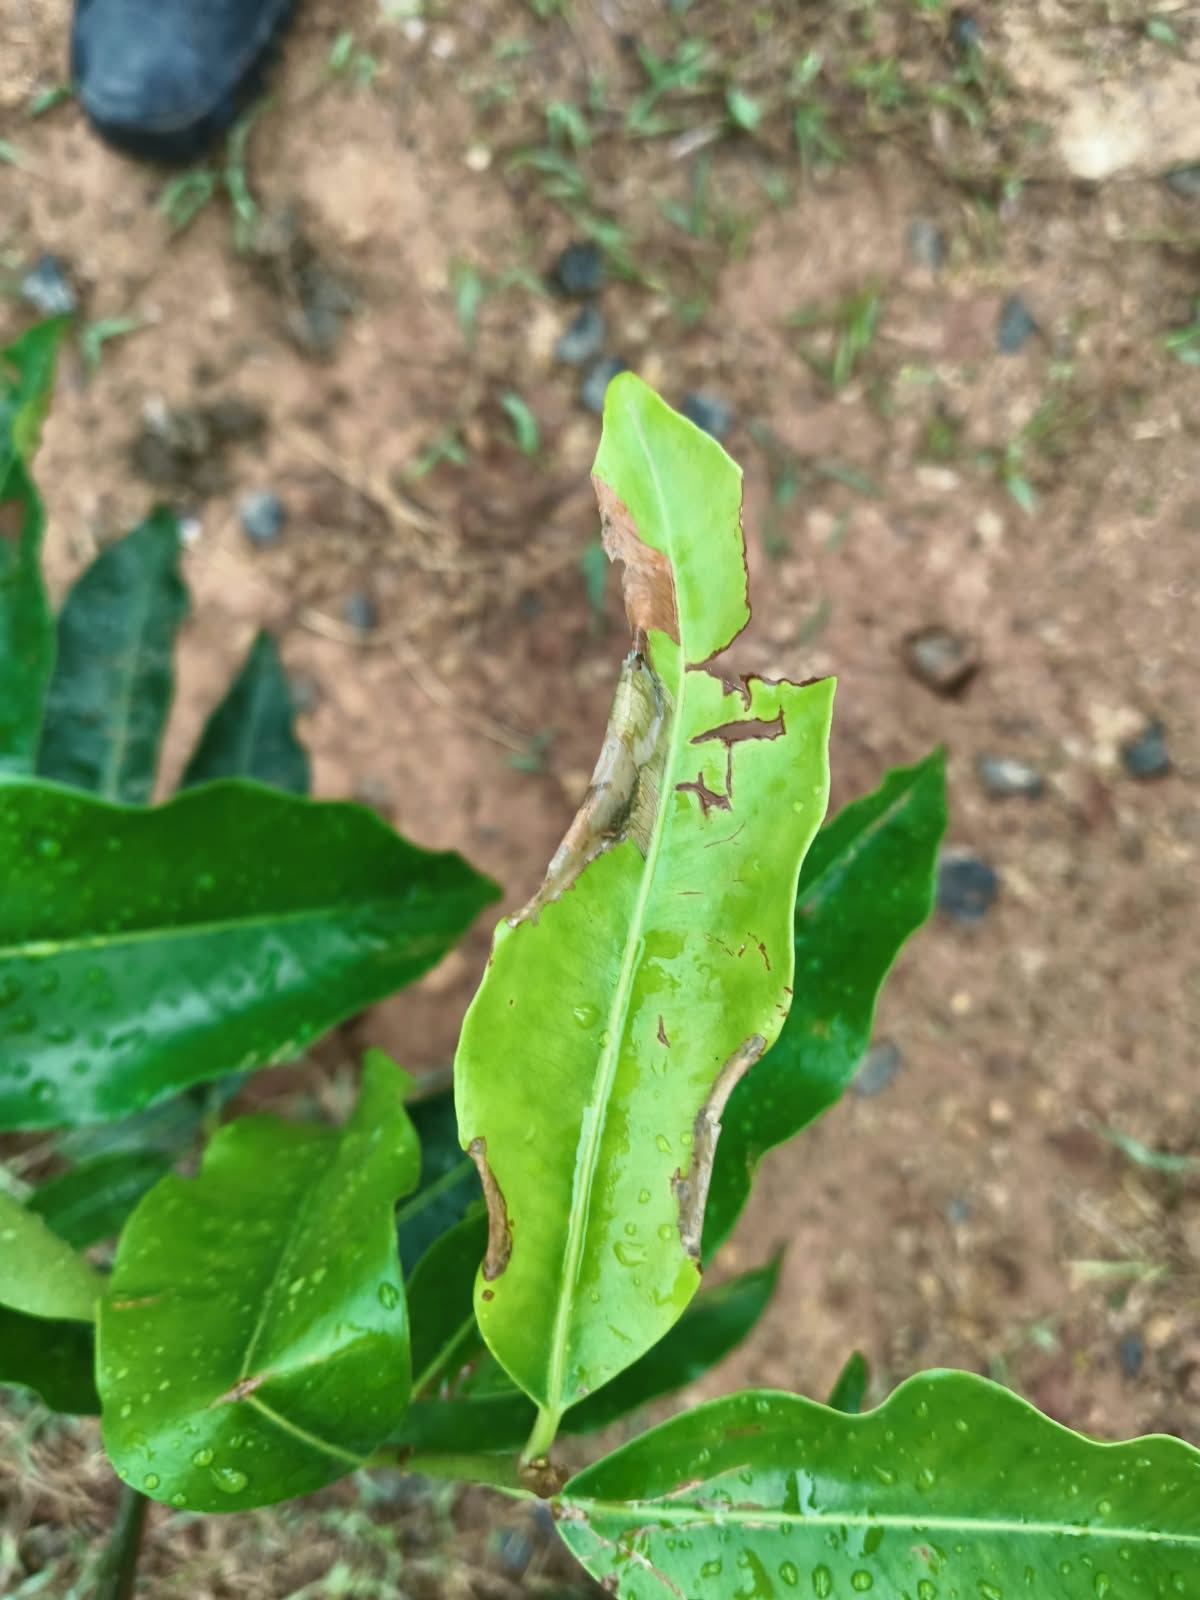


       CROP DISEASE DETECTION RESULT
Image: WhatsApp Image 2026-10-16 at 11.43.52 AM.jpeg
Predicted class: Tomato_Late_blight
Model confidence: 98.30%

Top 3 model predictions:
Tomato_Late_blight: 98.30%
Tomato_Early_blight: 1.29%
Tomato_Septoria_leaf_spot: 0.39%

DISEASE HAS BEEN DETECTED


In [ ]:

# Upload a leaf photo from your device
uploaded = files.upload()

for filename in uploaded.keys():
    # Display the uploaded image
    image = Image.open(filename).convert("RGB")
    print("Uploaded image:", filename)
    display(image)

    # Prepare the image for your trained model
    resized_image = image.resize((224, 224))
    image_array = np.array(resized_image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    # Predict the disease
    predictions = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(predictions))
    disease = class_names[predicted_index]
    confidence = float(predictions[predicted_index]) * 100

    print("\n" + "=" * 45)
    print("       CROP DISEASE DETECTION RESULT")
    print("=" * 45)
    print("Image:", filename)
    print("Predicted class:", disease)
    print(f"Model confidence: {confidence:.2f}%")
    print("=" * 45)

    # Show the three highest-scoring classes
    top_indices = np.argsort(predictions)[::-1][:3]
    print("\nTop 3 model predictions:")
    for i in top_indices:
        print(f"{class_names[int(i)]}: {float(predictions[i]) * 100:.2f}%")

    print("\nDISEASE HAS BEEN DETECTED")


In [1]:

!pip -q install gradio


In [4]:

import os
import json
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image

PROJECT_DIR = "/content/drive/MyDrive/Crop_Health_Project"
MODEL_PATH = os.path.join(PROJECT_DIR, "crop_disease_model.keras")
LABELS_PATH = os.path.join(PROJECT_DIR, "class_names.json")

# Load your trained model and labels
model = tf.keras.models.load_model(MODEL_PATH)

with open(LABELS_PATH, "r") as f:
    class_names = json.load(f)

if isinstance(class_names, dict):
    class_names = [class_names[str(i)] for i in range(len(class_names))]

def predict_disease(image):
    if image is None:
        return {}, "Please upload a leaf image."

    image = image.convert("RGB").resize((224, 224))
    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    predictions = model.predict(image_array, verbose=0)[0]
    top_indices = np.argsort(predictions)[::-1][:3]

    results = {
        str(class_names[int(i)]): float(predictions[int(i)])
        for i in top_indices
    }

    best_index = int(np.argmax(predictions))
    confidence = float(predictions[best_index]) * 100

    details = (
        f"**Predicted class:** {class_names[best_index]}\n\n"
        f"**Model confidence:** {confidence:.2f}%\n\n"
        "Note: This is an AI prediction, not a confirmed diagnosis. "
        "Results may be unreliable for crops or diseases outside the "
        "model's training classes."
    )

    return results, details

with gr.Blocks(theme=gr.themes.Soft(), title="Crop Health Detector") as demo:
    gr.Markdown(
        """
        # 🌿 Crop Health & Disease Monitoring
        ### AI-powered leaf disease classification
        Upload a clear crop leaf photo to see the model's prediction.
        """
    )

    with gr.Row():
        with gr.Column():
            image_input = gr.Image(
                type="pil",
                label="Upload a leaf image"
            )
            predict_button = gr.Button(
                "🔍 Detect Disease",
                variant="primary"
            )

        with gr.Column():
            prediction_output = gr.Label(
                label="Top predictions",
                num_top_classes=3
            )
            details_output = gr.Markdown(
                label="Prediction details"
            )

    predict_button.click(
        fn=predict_disease,
        inputs=image_input,
        outputs=[prediction_output, details_output]
    )

    gr.Markdown(
        "---\n"
        "Educational project demonstration. Confirm suspected diseases "
        "with a qualified agricultural expert before treatment."
    )

print("Model loaded:", model.input_shape, "→", model.output_shape)
print("Classes loaded:", len(class_names))

demo.launch(share=True)


/tmp/ipykernel_719/2063826526.py:50: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="Crop Health Detector") as demo:


Model loaded: (None, 224, 224, 3) → (None, 10)
Classes loaded: 10
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9c46a5afedf289c9cd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [3]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [5]:

import os

search_root = "/content/drive/MyDrive"

for root, dirs, files in os.walk(search_root):
    for name in files:
        if name == "crop_disease_model.keras":
            print("MODEL FOUND:", os.path.join(root, name))
        elif name == "class_names.json":
            print("LABELS FOUND:", os.path.join(root, name))


MODEL FOUND: /content/drive/MyDrive/Crop_Health_Project/crop_disease_model.keras
LABELS FOUND: /content/drive/MyDrive/Crop_Health_Project/class_names.json


In [6]:

import os

PROJECT_DIR = "/content/drive/MyDrive/Crop_Health_Project"
MODEL_PATH = os.path.join(PROJECT_DIR, "crop_disease_model.keras")
LABELS_PATH = os.path.join(PROJECT_DIR, "class_names.json")

print("Model exists:", os.path.exists(MODEL_PATH))
print("Labels exist:", os.path.exists(LABELS_PATH))


Model exists: True
Labels exist: True


In [7]:

import os
import json
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image

PROJECT_DIR = "/content/drive/MyDrive/Crop_Health_Project"
MODEL_PATH = os.path.join(PROJECT_DIR, "crop_disease_model.keras")
LABELS_PATH = os.path.join(PROJECT_DIR, "class_names.json")

# Load model and exact class labels
model = tf.keras.models.load_model(MODEL_PATH)

with open(LABELS_PATH, "r", encoding="utf-8") as f:
    class_names = json.load(f)

if isinstance(class_names, dict):
    class_names = [class_names[str(i)] for i in range(len(class_names))]

print("Model loaded successfully!")
print("Number of classes:", len(class_names))

def predict_disease(image):
    if image is None:
        return {}, "Please upload a leaf image."

    image = image.convert("RGB").resize((224, 224))
    array = np.array(image, dtype=np.float32) / 255.0
    array = np.expand_dims(array, axis=0)

    predictions = model.predict(array, verbose=0)[0]
    top_indices = np.argsort(predictions)[::-1][:3]

    top_predictions = {
        str(class_names[int(i)]): float(predictions[int(i)])
        for i in top_indices
    }

    best_index = int(np.argmax(predictions))
    confidence = float(predictions[best_index]) * 100

    details = (
        f"### Predicted class: {class_names[best_index]}\n\n"
        f"### Model confidence: {confidence:.2f}%\n\n"
        "This is an AI prediction, not a confirmed diagnosis. "
        "Confirm suspected disease with an agricultural expert."
    )

    return top_predictions, details

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Crop Health & Disease Monitoring"
) as demo:

    gr.Markdown("""
    # 🌿 Crop Health & Disease Monitoring
    ### AI-powered crop leaf disease detection

    Upload a leaf photograph and click **Detect Disease**.
    """)

    with gr.Row():
        with gr.Column():
            image_input = gr.Image(type="pil", label="Upload leaf image")
            detect_button = gr.Button("🔍 Detect Disease", variant="primary")

        with gr.Column():
            result_output = gr.Label(label="Top 3 predictions", num_top_classes=3)
            details_output = gr.Markdown()

    detect_button.click(
        fn=predict_disease,
        inputs=image_input,
        outputs=[result_output, details_output]
    )

    gr.Markdown("""
    ---
    **Note:** This project is for educational demonstration.
    Predictions may be unreliable for images outside the model's training classes.
    """)

demo.launch(share=True)


Model loaded successfully!
Number of classes: 10


/tmp/ipykernel_719/1008893677.py:52: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0cf0743210ec9fa6c8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
